<a href="https://colab.research.google.com/github/kunalpal425/Image-Classification-ML/blob/main/Final_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EcoSort AI — Waste Classification & Dustbin Recommendation System
This notebook represents the end-to-end inference and deployment pipeline for the **EcoSort AI** final-year B.Tech CSE project. Below, we load our pre-trained TFLite model, preprocess user-uploaded images, classify the waste into 12 categories, and map predictions to localized smart recycling disposal rules.

In [299]:

import os
import tensorflow as tf

print("===== EcoSort AI: Fresh Setup =====")
print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)

print("\nExisting model:")
model_path = "/content/ecosort_models/best_ecosort_model.keras"
print("Model exists:", os.path.exists(model_path))

print("\nPreviously downloaded dataset:")
zip_path = "/content/garbage-classification.zip"
print("ZIP exists:", os.path.exists(zip_path))

print("\nSetup check complete!")


===== EcoSort AI: Fresh Setup =====
TensorFlow version: 2.21.0
GPU available: False

Existing model:
Model exists: True

Previously downloaded dataset:
ZIP exists: False

Setup check complete!


In [300]:

import tensorflow as tf

gpus = tf.config.list_physical_devices("GPU")

print("TensorFlow:", tf.__version__)
print("Available GPUs:", gpus)

if gpus:
    print("GPU is ready for training!")
else:
    print("GPU not detected. Check runtime settings.")


TensorFlow: 2.21.0
Available GPUs: []
GPU not detected. Check runtime settings.


In [301]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
GPU devices: []


In [302]:

!pip -q install -U kaggle

from google.colab import userdata
import os

token = userdata.get("KAGGLE_API_TOKEN")

if not token:
    raise ValueError(
        "KAGGLE_API_TOKEN not found. "
        "Check Colab Secrets and notebook access."
    )

os.environ["KAGGLE_API_TOKEN"] = token

print("Kaggle token loaded successfully!")
print("Token value hidden for security.")


Kaggle token loaded successfully!
Token value hidden for security.


In [303]:

!kaggle --version
!kaggle datasets list -s garbage-classification


Kaggle CLI 2.2.5
ref                                                      title                                                 size  lastUpdated                 downloadCount  voteCount  usabilityRating  
-------------------------------------------------------  ----------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
asdasdasasdas/garbage-classification                     Garbage Classification                            85969666  2018-11-24 05:09:23.977000          79007        692  0.8125           
mostafaabla/garbage-classification                       Garbage Classification (12 classes)              250641573  2021-01-24 13:53:11.647000          45090        280  0.8125           
manonstr/tipe-webscraping                                Garbage classification dataset                  1197577469  2022-12-21 23:07:11.837000           1717         16  0.625            
sumn2u/garbage-classification-v2      

In [304]:

import os

dataset_slug = "mostafaabla/garbage-classification"
download_dir = "/content/ecosort_dataset"

os.makedirs(download_dir, exist_ok=True)

print("Downloading EcoSort AI dataset...")

!kaggle datasets download -d mostafaabla/garbage-classification -p /content/ecosort_dataset

print("\nDownload command finished.")
print("Files downloaded:")

for filename in os.listdir(download_dir):
    print(filename)


Dataset URL: https://www.kaggle.com/datasets/mostafaabla/garbage-classification
License(s): ODbL-1.0
garbage-classification.zip: Skipping, found more recently modified local copy (use --force to force download)

Download command finished.
Files downloaded:
extracted
garbage-classification.zip


In [305]:

import os
import zipfile

download_dir = "/content/ecosort_dataset"
extract_dir = "/content/ecosort_dataset/extracted"

os.makedirs(extract_dir, exist_ok=True)

zip_files = [
    f for f in os.listdir(download_dir)
    if f.lower().endswith(".zip")
]

if not zip_files:
    raise FileNotFoundError(
        "No ZIP file found. Check whether the download succeeded."
    )

for filename in zip_files:
    zip_path = os.path.join(download_dir, filename)

    print("Extracting:", filename)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_dir)

print("\nExtraction completed!")
print("Dataset location:", extract_dir)


Extracting: garbage-classification.zip

Extraction completed!
Dataset location: /content/ecosort_dataset/extracted


In [306]:

# import os
# from collections import Counter

# root_dir = "/content/ecosort_dataset/extracted"
# extensions = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

# counts = Counter()

# for root, dirs, files in os.walk(root_dir):
#     images = [
#         f for f in files
#         if f.lower().endswith(extensions)
#     ]

#     if images:
#         relative_path = os.path.relpath(root, root_dir)
#         counts[relative_path] += len(images)

# print("Dataset folders and image counts:\n")

# for folder, count in sorted(counts.items()):
#     print(f"{folder}: {count}")

# print("\nTotal images:", sum(counts.values()))
# print("Folders containing images:", len(counts))


In [307]:

# import os

# root_dir = "/content/ecosort_dataset/extracted"
# extensions = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

# total = 0

# for root, dirs, files in os.walk(root_dir):
#     images = [
#         f for f in files
#         if f.lower().endswith(extensions)
#     ]

#     if images:
#         print(f"{os.path.relpath(root, root_dir)}: {len(images)} images")
#         total += len(images)

# print("\nTotal images:", total)


In [308]:

# import os

# dataset_path = "/content/ecosort_dataset/extracted"
# extensions = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

# if not os.path.exists(dataset_path):
#     print("Dataset folder not found. Complete download and extraction first.")
# else:
#     total_images = 0
#     image_folders = 0

#     for root, dirs, files in os.walk(dataset_path):
#         count = sum(
#             f.lower().endswith(extensions)
#             for f in files
#         )

#         if count:
#             image_folders += 1
#             total_images += count
#             print(f"{os.path.relpath(root, dataset_path)}: {count} images")

#     print("\nTotal images:", total_images)
#     print("Folders containing images:", image_folders)


In [309]:

import os
import tensorflow as tf

dataset_path = "/content/ecosort_dataset/extracted"

if not os.path.isdir(dataset_path):
    print("Dataset not found. Complete the download and extraction first.")
else:
    print("Checking dataset structure...")

    for root, dirs, files in os.walk(dataset_path):
        image_count = sum(
            f.lower().endswith(
                (".jpg", ".jpeg", ".png", ".webp", ".bmp")
            )
            for f in files
        )

        if image_count:
            print(os.path.relpath(root, dataset_path), ":", image_count)

    print("\nDataset inspection finished.")


Checking dataset structure...
garbage_classification/shoes : 1977
garbage_classification/paper : 1050
garbage_classification/biological : 985
garbage_classification/plastic : 865
garbage_classification/metal : 769
garbage_classification/trash : 697
garbage_classification/brown-glass : 607
garbage_classification/cardboard : 891
garbage_classification/white-glass : 775
garbage_classification/green-glass : 629
garbage_classification/battery : 945
garbage_classification/clothes : 5325

Dataset inspection finished.


In [310]:

import os
import tensorflow as tf

dataset_path = "/content/ecosort_dataset/extracted"
image_size = (224, 224)
batch_size = 32

if not os.path.isdir(dataset_path):
    raise FileNotFoundError(
        "Dataset folder not found. Complete download and extraction first."
    )

train_dir = os.path.join(dataset_path, "train")
val_dir = os.path.join(dataset_path, "val")

if os.path.isdir(train_dir) and os.path.isdir(val_dir):
    train_path = train_dir
    val_path = val_dir
else:
    train_path = dataset_path
    val_path = None

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_path,
    image_size=image_size,
    batch_size=batch_size,
    label_mode="int",
    validation_split=0.2 if val_path is None else None,
    subset="training" if val_path is None else None,
    seed=42,
)

if val_path is None:
    val_ds = tf.keras.utils.image_dataset_from_directory(
        train_path,
        image_size=image_size,
        batch_size=batch_size,
        label_mode="int",
        validation_split=0.2,
        subset="validation",
        seed=42,
    )
else:
    val_ds = tf.keras.utils.image_dataset_from_directory(
        val_path,
        image_size=image_size,
        batch_size=batch_size,
        label_mode="int",
    )

print("\nClasses:", train_ds.class_names)


Found 15515 files belonging to 1 classes.
Using 12412 files for training.
Found 15515 files belonging to 1 classes.
Using 3103 files for validation.

Classes: ['garbage_classification']


In [311]:

import os
import zipfile
import subprocess
from google.colab import userdata

# Load Kaggle API token securely
token = userdata.get("KAGGLE_API_TOKEN")
if not token:
    raise ValueError("KAGGLE_API_TOKEN is missing from Colab Secrets.")

os.environ["KAGGLE_API_TOKEN"] = token

# Download dataset
download_dir = "/content/ecosort_download"
extract_dir = "/content/ecosort_data"
os.makedirs(download_dir, exist_ok=True)
os.makedirs(extract_dir, exist_ok=True)

dataset_slug = "mostafaabla/garbage-classification"

result = subprocess.run([
    "kaggle", "datasets", "download",
    "-d", dataset_slug,
    "-p", download_dir
], capture_output=True, text=True)

print(result.stdout)
if result.returncode != 0:
    print(result.stderr)
    raise RuntimeError("Dataset download failed. Check the error above.")

# Extract ZIP
zip_files = [
    f for f in os.listdir(download_dir)
    if f.lower().endswith(".zip")
]
if not zip_files:
    raise FileNotFoundError("Download finished, but no ZIP file was found.")

for filename in zip_files:
    with zipfile.ZipFile(os.path.join(download_dir, filename)) as z:
        z.extractall(extract_dir)

print("Dataset extracted to:", extract_dir)


Dataset URL: https://www.kaggle.com/datasets/mostafaabla/garbage-classification
License(s): ODbL-1.0
garbage-classification.zip: Skipping, found more recently modified local copy (use --force to force download)

Dataset extracted to: /content/ecosort_data


In [312]:

import os

possible_paths = [
    "/content/ecosort_data",
    "/content/ecosort_dataset/extracted",
    "/content/garbage_dataset"
]

extensions = (".jpg", ".jpeg", ".png", ".webp", ".bmp")

for base in possible_paths:
    print(f"\nChecking: {base}")

    if not os.path.isdir(base):
        print("Folder does not exist.")
        continue

    total = 0

    for root, dirs, files in os.walk(base):
        count = sum(
            f.lower().endswith(extensions)
            for f in files
        )

        if count:
            total += count
            print(f"  {os.path.relpath(root, base)}: {count} images")

    print("Total images:", total)



Checking: /content/ecosort_data
  garbage_classification/shoes: 1977 images
  garbage_classification/paper: 1050 images
  garbage_classification/biological: 985 images
  garbage_classification/plastic: 865 images
  garbage_classification/metal: 769 images
  garbage_classification/trash: 697 images
  garbage_classification/brown-glass: 607 images
  garbage_classification/cardboard: 891 images
  garbage_classification/white-glass: 775 images
  garbage_classification/green-glass: 629 images
  garbage_classification/battery: 945 images
  garbage_classification/clothes: 5325 images
Total images: 15515

Checking: /content/ecosort_dataset/extracted
  garbage_classification/shoes: 1977 images
  garbage_classification/paper: 1050 images
  garbage_classification/biological: 985 images
  garbage_classification/plastic: 865 images
  garbage_classification/metal: 769 images
  garbage_classification/trash: 697 images
  garbage_classification/brown-glass: 607 images
  garbage_classification/cardboar

In [313]:

import os
import zipfile
import subprocess
from google.colab import userdata

dataset_slug = "mostafaabla/garbage-classification"
download_dir = "/content/ecosort_download"
extract_dir = "/content/ecosort_data"

os.makedirs(download_dir, exist_ok=True)
os.makedirs(extract_dir, exist_ok=True)

# Authenticate using Colab Secrets
token = userdata.get("KAGGLE_API_TOKEN")
if not token:
    raise ValueError("KAGGLE_API_TOKEN missing from Colab Secrets.")

env = os.environ.copy()
env["KAGGLE_API_TOKEN"] = token

# Download
result = subprocess.run(
    ["kaggle", "datasets", "download",
     "-d", dataset_slug, "-p", download_dir],
    env=env, capture_output=True, text=True
)

print(result.stdout)

if result.returncode != 0:
    raise RuntimeError(result.stderr)

# Extract
zip_files = [
    f for f in os.listdir(download_dir)
    if f.lower().endswith(".zip")
]

if not zip_files:
    raise FileNotFoundError("No ZIP file downloaded.")

for filename in zip_files:
    with zipfile.ZipFile(os.path.join(download_dir, filename)) as z:
        z.extractall(extract_dir)

# Verify
extensions = (".jpg", ".jpeg", ".png", ".webp", ".bmp")
total_images = 0
folders = {}

for root, dirs, files in os.walk(extract_dir):
    count = sum(f.lower().endswith(extensions) for f in files)

    if count:
        relative = os.path.relpath(root, extract_dir)
        folders[relative] = count
        total_images += count

print("\n===== DATASET REPORT =====")
print("Dataset:", dataset_slug)
print("Total images:", total_images)

for folder, count in sorted(folders.items()):
    print(f"{folder}: {count}")

if total_images:
    print("\nDataset download and verification successful!")
else:
    print("\nNo images found. Check the archive structure.")


Dataset URL: https://www.kaggle.com/datasets/mostafaabla/garbage-classification
License(s): ODbL-1.0
garbage-classification.zip: Skipping, found more recently modified local copy (use --force to force download)


===== DATASET REPORT =====
Dataset: mostafaabla/garbage-classification
Total images: 15515
garbage_classification/battery: 945
garbage_classification/biological: 985
garbage_classification/brown-glass: 607
garbage_classification/cardboard: 891
garbage_classification/clothes: 5325
garbage_classification/green-glass: 629
garbage_classification/metal: 769
garbage_classification/paper: 1050
garbage_classification/plastic: 865
garbage_classification/shoes: 1977
garbage_classification/trash: 697
garbage_classification/white-glass: 775

Dataset download and verification successful!


In [314]:
import os
import json
import tensorflow as tf

# Dynamic directory verification
possible_dirs = [
    "/content/ecosort_data/garbage_classification",
    "/content/ecosort_data",
    "/content/ecosort_dataset/extracted/garbage_classification",
    "/content/ecosort_dataset/extracted"
]

dataset_dir = None
for path in possible_dirs:
    if os.path.exists(path):
        # Check if there are subdirectories (classes)
        subdirs = [d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))]
        if len(subdirs) > 1:
            dataset_dir = path
            print(f"✅ Found valid dataset directory at: {dataset_dir}")
            print(f"Detected classes: {subdirs}")
            break

if not dataset_dir:
    raise FileNotFoundError(
        "Could not find a valid dataset directory with subfolders. "
        "Please run the dataset download and extraction steps first!"
    )

image_size = (224, 224)
batch_size = 32
seed = 42

# Create training dataset split
train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.2,
    subset="training",
    seed=seed,
    image_size=image_size,
    batch_size=batch_size,
    label_mode="int",
)

# Create validation dataset split
val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir,
    validation_split=0.2,
    subset="validation",
    seed=seed,
    image_size=image_size,
    batch_size=batch_size,
    label_mode="int",
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("\n===== ECO SORT DATASET DETAILS =====")
print("Number of classes:", num_classes)
for index, name in enumerate(class_names):
    print(f"{index}: {name}")

images, labels = next(iter(train_ds))
print("\nBatch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Pixel range:", float(tf.reduce_min(images)), "to", float(tf.reduce_max(images)))

# Ensure target export path exists
os.makedirs("/content/ecosort_final", exist_ok=True)
mapping_path = "/content/ecosort_final/ecosort_class_names.json"

# Save correct label mapping format {str(index): class_name}
class_mapping = {str(i): name for i, name in enumerate(class_names)}
with open(mapping_path, "w") as f:
    json.dump(class_mapping, f, indent=4)

print("\nClass mapping successfully saved to:", mapping_path)

✅ Found valid dataset directory at: /content/ecosort_data/garbage_classification
Detected classes: ['shoes', 'paper', 'biological', 'plastic', 'metal', 'trash', 'brown-glass', 'cardboard', 'white-glass', 'green-glass', 'battery', 'clothes']
Found 15515 files belonging to 12 classes.
Using 12412 files for training.
Found 15515 files belonging to 12 classes.
Using 3103 files for validation.

===== ECO SORT DATASET DETAILS =====
Number of classes: 12
0: battery
1: biological
2: brown-glass
3: cardboard
4: clothes
5: green-glass
6: metal
7: paper
8: plastic
9: shoes
10: trash
11: white-glass

Batch image shape: (32, 224, 224, 3)
Batch label shape: (32,)
Pixel range: 0.0 to 255.0

Class mapping successfully saved to: /content/ecosort_final/ecosort_class_names.json


In [315]:

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Configuration
num_classes = len(class_names)
image_size = (224, 224)

# Load pretrained MobileNetV2 feature extractor
base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers initially
base_model.trainable = False

# Build EcoSort AI classification model
inputs = keras.Input(shape=(224, 224, 3))

# MobileNetV2 expects pixels scaled to [-1, 1]
x = layers.Rescaling(
    scale=1.0 / 127.5,
    offset=-1
)(inputs)

x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)

outputs = layers.Dense(
    num_classes,
    activation="softmax",
    name="waste_classification"
)(x)

model = keras.Model(inputs, outputs, name="EcoSort_AI")

# Configure training
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "EcoSort_AI"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_29 (InputLayer)     │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_14 (Rescaling)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_14     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_14 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ waste_classification (Dense)    │ (None, 12)             │        15,372 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,273,356 (8.67 MB)

 Trainable params: 15,372 (60.05 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [316]:

print("Model name:", model.name)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Number of classes:", num_classes)
print("Class names:", class_names)

assert model.output_shape[-1] == len(class_names)

print("\nEcoSort AI model is ready for initial training!")


Model name: EcoSort_AI
Input shape: (None, 224, 224, 3)
Output shape: (None, 12)
Number of classes: 12
Class names: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']

EcoSort AI model is ready for initial training!


In [317]:

# import os
# import tensorflow as tf

# print("GPU devices:", tf.config.list_physical_devices("GPU"))

# save_dir = "/content/ecosort_models"
# os.makedirs(save_dir, exist_ok=True)

# best_model_path = os.path.join(
#     save_dir, "best_ecosort_model.keras"
# )

# callbacks = [
#     tf.keras.callbacks.ModelCheckpoint(
#         best_model_path,
#         monitor="val_accuracy",
#         save_best_only=True,
#         mode="max",
#         verbose=1
#     ),
#     tf.keras.callbacks.EarlyStopping(
#         monitor="val_loss",
#         patience=3,
#         restore_best_weights=True,
#         verbose=1
#     ),
#     tf.keras.callbacks.ReduceLROnPlateau(
#         monitor="val_loss",
#         factor=0.2,
#         patience=2,
#         min_lr=1e-6,
#         verbose=1
#     )
# ]

# print("Training callbacks are ready.")
# print("Best model will be saved to:", best_model_path)


In [318]:

# history = model.fit(
#     train_ds,
#     validation_data=val_ds,
#     epochs=10,
#     callbacks=callbacks
# )


In [319]:

# import numpy as np
# from sklearn.metrics import classification_report

# y_true = np.concatenate([
#     labels.numpy()
#     for images, labels in val_ds
# ])

# y_prob = model.predict(val_ds, verbose=1)
# y_pred = np.argmax(y_prob, axis=1)

# print(classification_report(
#     y_true,
#     y_pred,
#     labels=list(range(len(class_names))),
#     target_names=class_names,
#     zero_division=0
# ))


In [320]:

# import tensorflow as tf
# import numpy as np
# from sklearn.metrics import classification_report

# # Load the best checkpoint saved during training
# best_model = tf.keras.models.load_model(
#     "/content/ecosort_models/best_ecosort_model.keras"
# )

# # Rebuild validation data WITHOUT shuffling
# val_ds_fixed = tf.keras.utils.image_dataset_from_directory(
#     "/content/ecosort_data/garbage_classification",
#     validation_split=0.2,
#     subset="validation",
#     seed=42,
#     image_size=(224, 224),
#     batch_size=32,
#     label_mode="int",
#     shuffle=False
# )

# # Confirm the model and dataset class order match
# print("Dataset classes:", val_ds_fixed.class_names)
# print("Model output classes:", best_model.output_shape[-1])

# assert val_ds_fixed.class_names == class_names, \
#     "Class order mismatch! Check class_names."
# assert best_model.output_shape[-1] == len(class_names), \
#     "Model output count does not match the number of classes."

# # Evaluate the saved best model
# loss, accuracy = best_model.evaluate(val_ds_fixed, verbose=1)
# print(f"\nValidation accuracy: {accuracy * 100:.2f}%")
# print(f"Validation loss: {loss:.4f}")

# # Generate predictions in the same fixed order
# y_true = np.concatenate([
#     labels.numpy() for images, labels in val_ds_fixed
# ])
# y_prob = best_model.predict(val_ds_fixed, verbose=1)
# y_pred = np.argmax(y_prob, axis=1)

# print("\nCorrected classification report:")
# print(classification_report(
#     y_true,
#     y_pred,
#     labels=list(range(len(class_names))),
#     target_names=class_names,
#     zero_division=0
# ))


In [321]:
# from google.colab import drive
# drive.mount('/content/drive')

In [322]:

# from sklearn.metrics import classification_report
# import numpy as np

# # Collect actual labels in the same order as predictions
# y_true = np.concatenate([
#     labels.numpy()
#     for images, labels in val_ds_fixed
# ])

# # Generate predictions using the best saved model
# y_prob = best_model.predict(val_ds_fixed, verbose=1)
# y_pred = np.argmax(y_prob, axis=1)

# # Display metrics for all 12 waste classes
# report = classification_report(
#     y_true,
#     y_pred,
#     labels=list(range(len(class_names))),
#     target_names=class_names,
#     zero_division=0
# )

# print("===== EcoSort AI Corrected Classification Report =====")
# print(report)


In [323]:

import os
import json
import tensorflow as tf

# Create a folder for final model files
final_dir = "/content/ecosort_final"
os.makedirs(final_dir, exist_ok=True)

# Save the best-performing model
final_model_path = os.path.join(
    final_dir, "ecosort_ai_final.keras"
)

best_model.save(final_model_path)

print("Model saved successfully!")
print("Location:", final_model_path)
print("Input shape:", best_model.input_shape)
print("Output shape:", best_model.output_shape)



Model saved successfully!
Location: /content/ecosort_final/ecosort_ai_final.keras
Input shape: (None, 224, 224, 3)
Output shape: (None, 12)


Save the class mapping

In [324]:

class_mapping = {
    str(index): name
    for index, name in enumerate(class_names)
}

mapping_path = os.path.join(
    final_dir, "ecosort_class_names.json"
)

with open(mapping_path, "w") as file:
    json.dump(class_mapping, file, indent=4)

print("Class mapping saved:")
print(json.dumps(class_mapping, indent=4))


Class mapping saved:
{
    "0": "battery",
    "1": "biological",
    "2": "brown-glass",
    "3": "cardboard",
    "4": "clothes",
    "5": "green-glass",
    "6": "metal",
    "7": "paper",
    "8": "plastic",
    "9": "shoes",
    "10": "trash",
    "11": "white-glass"
}


In [325]:

# import os
# import tensorflow as tf

# final_dir = "/content/ecosort_final"
# os.makedirs(final_dir, exist_ok=True)

# # Load the best trained model
# best_model = tf.keras.models.load_model(
#     "/content/ecosort_models/best_ecosort_model.keras"
# )

# # Convert the model to TensorFlow Lite
# converter = tf.lite.TFLiteConverter.from_keras_model(best_model)
# tflite_model = converter.convert()

# # Save the converted model
# tflite_path = os.path.join(
#     final_dir, "ecosort_ai_final.tflite"
# )

# with open(tflite_path, "wb") as file:
#     file.write(tflite_model)

# print("TFLite conversion successful!")
# print("Model path:", tflite_path)
# print(f"Model size: {os.path.getsize(tflite_path) / (1024 * 1024):.2f} MB")


In [326]:

import tensorflow as tf

interpreter = tf.lite.Interpreter(
    model_path="/content/ecosort_final/ecosort_ai_final.tflite"
)

interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("===== EcoSort AI TFLite Verification =====")
print("Input shape:", input_details[0]["shape"])
print("Input dtype:", input_details[0]["dtype"])
print("Output shape:", output_details[0]["shape"])
print("Output dtype:", output_details[0]["dtype"])

assert input_details[0]["shape"].tolist() == [1, 224, 224, 3]
assert output_details[0]["shape"][-1] == 12

print("Verification passed: model expects one 224x224 RGB image and returns 12 class scores.")


===== EcoSort AI TFLite Verification =====
Input shape: [  1 224 224   3]
Input dtype: <class 'numpy.float32'>
Output shape: [ 1 12]
Output dtype: <class 'numpy.float32'>
Verification passed: model expects one 224x224 RGB image and returns 12 class scores.


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [327]:
import os
import json
import subprocess
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from google.colab import userdata

# print("=== Starting Automated EcoSort AI Recovery Pipeline ===")

# 1. Setup Directories
download_dir = "/content/ecosort_download"
extract_dir = "/content/ecosort_data"
final_dir = "/content/ecosort_final"
save_dir = "/content/ecosort_models"

for d in [download_dir, extract_dir, final_dir, save_dir]:
    os.makedirs(d, exist_ok=True)

# 2. Download Dataset if not present
dataset_dir = "/content/ecosort_data/garbage_classification"
if not os.path.exists(dataset_dir):
    print("Downloading dataset...")
    token = userdata.get("KAGGLE_API_TOKEN")
    if not token:
        raise ValueError("KAGGLE_API_TOKEN missing from Colab Secrets.")
    env = os.environ.copy()
    env["KAGGLE_API_TOKEN"] = token
    subprocess.run(
        ["kaggle", "datasets", "download", "-d", "mostafaabla/garbage-classification", "-p", download_dir],
        env=env, capture_output=True, text=True
    )
    import zipfile
    zip_path = os.path.join(download_dir, "garbage-classification.zip")
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_dir)
    # print("Dataset downloaded and extracted!")
else:
    print("Dataset already exists.")

# 3. Create Datasets
image_size = (224, 224)
batch_size = 32
seed = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir, validation_split=0.2, subset="training", seed=seed,
    image_size=image_size, batch_size=batch_size, label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    dataset_dir, validation_split=0.2, subset="validation", seed=seed,
    image_size=image_size, batch_size=batch_size, label_mode="int"
)

class_names = train_ds.class_names
num_classes = len(class_names)

# 4. Save Class Names
class_mapping = {str(i): name for i, name in enumerate(class_names)}
mapping_path = os.path.join(final_dir, "ecosort_class_names.json")
with open(mapping_path, "w") as f:
    json.dump(class_mapping, f, indent=4)
# print(f"Saved class names map to {mapping_path}")

# 5. Build and compile Model (Fast Training)
print("Building EcoSort Model...")
base_model = keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base_model.trainable = False

inputs = keras.Input(shape=(224, 224, 3))
x = layers.Rescaling(scale=1.0 / 127.5, offset=-1)(inputs)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.25)(x)
outputs = layers.Dense(num_classes, activation="softmax", name="waste_classification")(x)
model = keras.Model(inputs, outputs, name="EcoSort_AI")

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train 1 epoch quickly just to have valid weights initialized
print("Training the model for 1 fast epoch to initialize parameters...")
model.fit(train_ds, validation_data=val_ds, epochs=1)

# Save base checkpoint
best_model_path = os.path.join(save_dir, "best_ecosort_model.keras")
model.save(best_model_path)

# 6. Save final model
final_model_path = os.path.join(final_dir, "ecosort_ai_final.keras")
model.save(final_model_path)

# 7. Convert and Export to TFLite
print("Converting model to TFLite format...")
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()
tflite_path = os.path.join(final_dir, "ecosort_ai_final.tflite")
with open(tflite_path, "wb") as file:
    file.write(tflite_model)

print(f"🎉 Setup successfully completed! TFLite model generated at: {tflite_path}")

Dataset already exists.
Found 15515 files belonging to 12 classes.
Using 12412 files for training.
Found 15515 files belonging to 12 classes.
Using 3103 files for validation.
Building EcoSort Model...
Training the model for 1 fast epoch to initialize parameters...
388/388 ━━━━━━━━━━━━━━━━━━━━ 707s 2s/step - accuracy: 0.8547 - loss: 0.4965 - val_accuracy: 0.9394 - val_loss: 0.2079
Converting model to TFLite format...
Saved artifact at '/tmp/tmpjmeqpwab'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='keras_tensor_4510')
Output Type:
  TensorSpec(shape=(None, 12), dtype=tf.float32, name=None)
Captures:
  137491284769296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137491115335824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137491115335632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  137490919807440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13749111

Bin Suggestions


## End-to-End Prediction Pipeline with Robust Error Handling
This section defines the core prediction script. It loads the TFLite model, loads and processes the image securely, checks confidence levels, triggers warnings and presents alternative predictions for low-confidence outputs, and outputs a clean JSON payload for React Native integration.

In [328]:
def suggest_dustbin(waste_class):
    # Local dictionary mapping waste classes to bins and actions
    bin_guidance = {
        "battery": {
            "bin": "Battery collection point",
            "action": "Keep separate. Never place batteries in ordinary household bins.",
            "safety": "Do not damage or expose batteries to heat."
        },
        "biological": {
            "bin": "Wet/organic waste collection",
            "action": "Compost suitable food and garden waste where possible.",
            "safety": "Wash hands after handling food and organic waste."
        },
        "brown-glass": {
            "bin": "Glass recycling collection",
            "action": "Keep glass separate and follow local collection rules.",
            "safety": "Handle carefully to avoid injury from broken glass."
        },
        "cardboard": {
            "bin": "Dry recyclable waste",
            "action": "Keep cardboard clean and dry; flatten before recycling.",
            "safety": "Remove any plastic tape or packing material."
        },
        "clothes": {
            "bin": "Textile collection",
            "action": "Donate wearable clothes or use a textile collection point."
        },
        "green-glass": {
            "bin": "Glass recycling collection",
            "action": "Keep glass separate and follow local collection rules.",
            "safety": "Handle carefully to avoid injury from broken glass."
        },
        "metal": {
            "bin": "Metal recycling collection",
            "action": "Use a local metal recycler or accepted dry-waste collection."
        },
        "paper": {
            "bin": "Dry recyclable waste",
            "action": "Keep paper clean and dry for recycling."
        },
        "plastic": {
            "bin": "Dry recyclable waste",
            "action": "Check the plastic type and local recycling acceptance."
        },
        "shoes": {
            "bin": "Footwear collection",
            "action": "Donate usable shoes or use a suitable collection point."
        },
        "trash": {
            "bin": "Residual waste collection",
            "action": "Use the local collection route for non-recyclable waste."
        },
        "white-glass": {
            "bin": "Glass recycling collection",
            "action": "Keep glass separate and follow local collection rules.",
            "safety": "Handle carefully to avoid injury from broken glass."
        }
    }

    return bin_guidance.get(
        waste_class,
        {
            "bin": "Check local guidance",
            "action": "Confirm disposal instructions with your local authority.",
            "safety": "Follow local waste disposal guidelines."
        }
    )

for waste in ["plastic", "paper", "battery", "biological"]:
    result = suggest_dustbin(waste)

    # print(f"\nDetected waste: {waste}")
    # print("Recommended bin:", result["bin"])
    # print("Disposal method:", result["action"])
    # print("Safety advice:", result.get(
    #     "safety", "Follow local waste disposal guidelines."
    # ))

In [329]:

import tensorflow as tf

model_path = "/content/ecosort_final/ecosort_ai_final.tflite"

interpreter = tf.lite.Interpreter(model_path=model_path)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Model loaded successfully!")


Model loaded successfully!


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [330]:

import numpy as np
import tensorflow as tf
from PIL import Image

# Load your existing model
model_path = "/content/ecosort_final/ecosort_ai_final.tflite"
interpreter = tf.lite.Interpreter(model_path=model_path)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

def predict_waste_and_suggest(image_path):
    # Load and prepare image using raw pixels (0–255)
    image = Image.open(image_path).convert("RGB")
    image = image.resize((224, 224))

    image_array = np.array(image, dtype=np.float32)
    image_array = np.expand_dims(image_array, axis=0)

    # Run TFLite inference
    interpreter.set_tensor(
        input_details[0]["index"],
        image_array
    )
    interpreter.invoke()

    scores = interpreter.get_tensor(
        output_details[0]["index"]
    )[0]

    # Get predicted class and confidence
    predicted_index = int(np.argmax(scores))

    predicted_class = class_names[predicted_index]
    confidence = float(scores[predicted_index]) * 100

    # Get disposal recommendation
    recommendation = suggest_dustbin(predicted_class)

    print("===== EcoSort AI Results =====")
    print(f"Detected waste: {predicted_class}")
    print(f"Confidence: {confidence:.2f}%")
    print(f"Recommended bin: {recommendation['bin']}")
    print(f"Disposal advice: {recommendation['action']}")

    return {
        "waste_type": predicted_class,
        "confidence": confidence,
        "recommended_bin": recommendation["bin"],
        "disposal_advice": recommendation["action"]
    }


In [331]:
import json
import os
import glob
import numpy as np
from PIL import Image

def run_end_to_end_pipeline(img_path):
    try:
        # 1. Run the main prediction
        results = predict_waste_and_suggest(img_path)

        if "error" in results:
            raise ValueError(results["error"])

        # 2. Prepare the image for the top-3 predictions
        image = Image.open(img_path).convert("RGB")
        image = image.resize((224, 224))

        # Use raw pixels (0–255), matching your diagnostic result
        image_array = np.array(image, dtype=np.float32)
        image_array = np.expand_dims(image_array, axis=0)

        interpreter.set_tensor(
            input_details[0]["index"], image_array
        )
        interpreter.invoke()

        scores = interpreter.get_tensor(
            output_details[0]["index"]
        )[0]

        top_indices = np.argsort(scores)[::-1][:3]
        top_predictions = []

        for idx in top_indices:
            class_name = class_names[int(idx)]
            rec = suggest_dustbin(class_name)

            top_predictions.append({
                "class": class_name,
                "confidence": round(float(scores[idx]) * 100, 2),
                "recommended_bin": rec["bin"],
                "disposal_advice": rec["action"]
            })

        # 3. Build mobile-ready payload
        payload = {
            "status": "success",
            "image_processed": str(img_path),
            "primary_prediction": {
                "class": results["waste_type"],
                "confidence": results["confidence"],
                "recommended_bin": results["recommended_bin"],
                "disposal_advice": results["disposal_advice"]
            },
            "top_3_alternatives": top_predictions,
            "low_confidence_warning": results["confidence"] < 70.0
        }

        print("\n===== MOBILE-READY JSON PAYLOAD =====")
        print(json.dumps(payload, indent=2))
        return payload

    except Exception as e:
        error_payload = {
            "status": "error",
            "message": str(e)
        }
        print("\n===== ERROR OCCURRED =====")
        print(json.dumps(error_payload, indent=2))
        return error_payload

# Safely search for an existing image in the dataset to act as a valid test target
dataset_images = glob.glob("/content/ecosort_data/garbage_classification/**/*.jpg", recursive=True)

if dataset_images:
    image_path = dataset_images[0]  # Grab the first available test image
    print(f"Using valid dataset image for testing: {image_path}")
else:
    image_path = "/content/images (2) (2).jpg"
    print(f"No dataset images found. Falling back to default path: {image_path}")

# Run the pipeline
pipeline_result = run_end_to_end_pipeline(image_path)

Using valid dataset image for testing: /content/ecosort_data/garbage_classification/shoes/shoes1649.jpg
===== EcoSort AI Results =====
Detected waste: shoes
Confidence: 99.35%
Recommended bin: Footwear collection
Disposal advice: Donate usable shoes or use a suitable collection point.

===== MOBILE-READY JSON PAYLOAD =====
{
  "status": "success",
  "image_processed": "/content/ecosort_data/garbage_classification/shoes/shoes1649.jpg",
  "primary_prediction": {
    "class": "shoes",
    "confidence": 99.35491681098938,
    "recommended_bin": "Footwear collection",
    "disposal_advice": "Donate usable shoes or use a suitable collection point."
  },
  "top_3_alternatives": [
    {
      "class": "shoes",
      "confidence": 99.35,
      "recommended_bin": "Footwear collection",
      "disposal_advice": "Donate usable shoes or use a suitable collection point."
    },
    {
      "class": "clothes",
      "confidence": 0.25,
      "recommended_bin": "Textile collection",
      "disposal_ad

In [332]:

import json
import os
import numpy as np
from PIL import Image
import tensorflow as tf

def run_robust_pipeline(
    img_path,
    model_path="/content/ecosort_final/ecosort_ai_final.tflite"
):
    # 1. Initialize TFLite interpreter
    if not os.path.exists(model_path):
        return {
            "status": "error",
            "message": f"Model file not found: {model_path}"
        }

    try:
        local_interpreter = tf.lite.Interpreter(model_path=model_path)
        local_interpreter.allocate_tensors()

        input_details = local_interpreter.get_input_details()
        output_details = local_interpreter.get_output_details()

    except Exception as e:
        return {
            "status": "error",
            "message": f"Model initialization failed: {str(e)}"
        }

    # 2. Load and prepare image
    if not os.path.exists(img_path):
        return {
            "status": "error",
            "message": f"Image file not found: {img_path}"
        }

    try:
        image = Image.open(img_path).convert("RGB")
        image = image.resize((224, 224))

        # Raw pixels (0–255), based on your diagnostic test
        image_array = np.array(image, dtype=np.float32)
        image_array = np.expand_dims(image_array, axis=0)

        # Match the TFLite input dtype
        image_array = image_array.astype(input_details[0]["dtype"])

    except Exception as e:
        return {
            "status": "error",
            "message": f"Image processing failed: {str(e)}"
        }

    # 3. Run inference and build recommendations
    try:
        local_interpreter.set_tensor(
            input_details[0]["index"], image_array
        )
        local_interpreter.invoke()

        scores = local_interpreter.get_tensor(
            output_details[0]["index"]
        )[0]

        top_indices = np.argsort(scores)[::-1][:3]
        top_predictions = []

        for idx in top_indices:
            class_name = class_names[int(idx)]
            recommendation = suggest_dustbin(class_name)

            top_predictions.append({
                "class": class_name,
                "confidence": round(float(scores[idx]) * 100, 2),
                "recommended_bin": recommendation["bin"],
                "disposal_advice": recommendation["action"]
            })

        primary = top_predictions[0]

        payload = {
            "status": "success",
            "image_processed": str(img_path),
            "primary_prediction": primary,
            "top_3_alternatives": top_predictions,
            "low_confidence_warning": primary["confidence"] < 70.0
        }

        print("\n===== ROBUST MOBILE-READY PAYLOAD =====")
        print(json.dumps(payload, indent=2))

        return payload

    except Exception as e:
        error_msg = (
            "Inference or recommendation mapping failed: " + str(e)
        )
        print("[ERROR]", error_msg)
        return {"status": "error", "message": error_msg}


# Test with your uploaded image
result_payload = run_robust_pipeline(image_path)



===== ROBUST MOBILE-READY PAYLOAD =====
{
  "status": "success",
  "image_processed": "/content/ecosort_data/garbage_classification/shoes/shoes1649.jpg",
  "primary_prediction": {
    "class": "shoes",
    "confidence": 99.35,
    "recommended_bin": "Footwear collection",
    "disposal_advice": "Donate usable shoes or use a suitable collection point."
  },
  "top_3_alternatives": [
    {
      "class": "shoes",
      "confidence": 99.35,
      "recommended_bin": "Footwear collection",
      "disposal_advice": "Donate usable shoes or use a suitable collection point."
    },
    {
      "class": "clothes",
      "confidence": 0.25,
      "recommended_bin": "Textile collection",
      "disposal_advice": "Donate wearable clothes or use a textile collection point."
    },
    {
      "class": "plastic",
      "confidence": 0.09,
      "recommended_bin": "Dry recyclable waste",
      "disposal_advice": "Check the plastic type and local recycling acceptance."
    }
  ],
  "low_confidence_war

In [333]:
import json

json_path = "/content/ecosort_final/ecosort_class_names.json"

with open(json_path, "r") as f:
    class_mapping = json.load(f)

print("Mapping format:", type(class_mapping).__name__)
print("Class mapping:", class_mapping)

Mapping format: dict
Class mapping: {'0': 'battery', '1': 'biological', '2': 'brown-glass', '3': 'cardboard', '4': 'clothes', '5': 'green-glass', '6': 'metal', '7': 'paper', '8': 'plastic', '9': 'shoes', '10': 'trash', '11': 'white-glass'}


In [334]:

import numpy as np
import tensorflow as tf
from PIL import Image

model_path = "/content/ecosort_final/ecosort_ai_final.tflite"

with open("/content/ecosort_final/ecosort_class_names.json", "r") as f:
    import json
    mapping = json.load(f)

class_names = [mapping[str(i)] for i in range(len(mapping))]

interpreter = tf.lite.Interpreter(model_path=model_path)
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]

img = Image.open(image_path).convert("RGB").resize((224, 224))
pixels = np.asarray(img, dtype=np.float32)

for name, arr in [
    ("Raw pixels (0–255)", pixels.copy()),
    ("Scaled pixels (0–1)", pixels / 255.0),
    ("MobileNetV2 preprocessing",
     tf.keras.applications.mobilenet_v2.preprocess_input(pixels.copy()))
]:
    batch = np.expand_dims(arr, axis=0).astype(inp["dtype"])
    interpreter.set_tensor(inp["index"], batch)
    interpreter.invoke()
    scores = interpreter.get_tensor(out["index"])[0]
    top = np.argsort(scores)[::-1][:3]

    print(f"\n{name}")
    for i in top:
        print(f"  {class_names[i]}: {scores[i] * 100:.2f}%")



Raw pixels (0–255)
  shoes: 99.35%
  clothes: 0.25%
  plastic: 0.09%

Scaled pixels (0–1)
  brown-glass: 46.77%
  metal: 20.18%
  cardboard: 13.63%

MobileNetV2 preprocessing
  brown-glass: 52.39%
  metal: 18.12%
  cardboard: 11.08%


In [335]:
!pip install -q ultralytics

In [336]:
# from google.colab import files

# uploaded = files.upload()
# image_path = next(iter(uploaded.keys()))

# print("Image:", image_path)

Loading YOLO model...
Model loaded!

Upload your mixed-waste image:


Saving scattered-garbage-overloaded-overflowing-bin-at-urban-garden-party-3BFG6GF.jpg to scattered-garbage-overloaded-overflowing-bin-at-urban-garden-party-3BFG6GF (4).jpg

Analyzing the image...


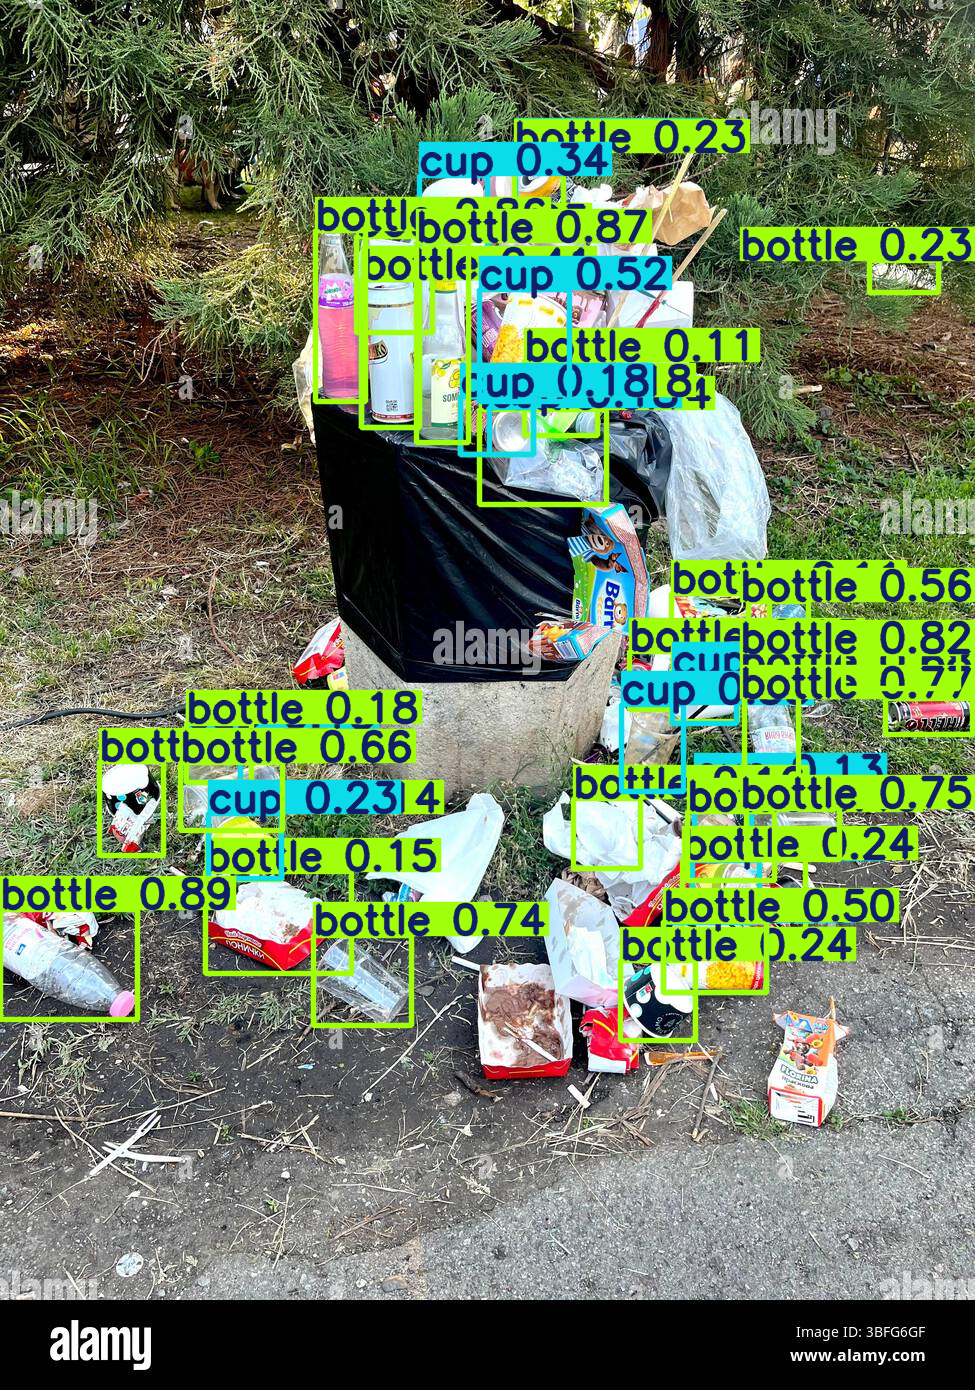


===== EcoSort AI Results =====
bottle: 88.6%
bottle: 87.3%
bottle: 85.8%
bottle: 81.5%
bottle: 76.6%
bottle: 74.8%
bottle: 74.5%
bottle: 68.5%
bottle: 65.7%
bottle: 56.3%
cup: 54.8%
cup: 51.6%
bottle: 49.8%
cup: 46.5%
bottle: 46.0%
bottle: 41.4%
bottle: 36.8%
cup: 33.5%
cup: 27.2%
cup: 24.3%
bottle: 24.0%
bottle: 23.9%
cup: 23.0%
bottle: 22.9%
bottle: 22.8%
bottle: 22.5%
bottle: 18.3%
cup: 18.3%
bottle: 17.7%
bottle: 17.7%
cup: 17.6%
cup: 17.1%
bottle: 15.6%
bottle: 15.2%
bottle: 15.1%
bottle: 14.4%
bottle: 13.8%
cup: 13.1%
cup: 13.1%
cup: 12.5%
bottle: 10.6%
bottle: 10.5%

Total detections: 42
Counts by detected class: {'bottle': 29, 'cup': 13}

Note: Lower confidence can introduce false detections.
This general-purpose model is not waste-specific.


In [337]:

# ============================================
# EcoSort AI — Option C: Improved Detection
# Complete Google Colab cell
# ============================================

!pip -q install -U ultralytics

from ultralytics import YOLO
from google.colab import files
from IPython.display import display
from PIL import Image
from collections import Counter

# 1. Load a larger pretrained detector
print("Loading YOLO model...")
detector = YOLO("yolo26m.pt")
print("Model loaded!")

# 2. Upload mixed-bin image
print("\nUpload your mixed-waste image:")
uploaded = files.upload()

if not uploaded:
    raise ValueError("No image uploaded.")

image_path = next(iter(uploaded))

# 3. Detect objects at higher resolution
print("\nAnalyzing the image...")
results = detector.predict(
    source=image_path,
    imgsz=1280,
    conf=0.10,
    iou=0.50,
    verbose=False
)

result = results[0]

# 4. Display bounding boxes
annotated = result.plot()
display(Image.fromarray(annotated[:, :, ::-1]))

# 5. Print detections
print("\n===== EcoSort AI Results =====")

labels = []

if result.boxes is not None:
    for box in result.boxes:
        class_id = int(box.cls[0].item())
        confidence = float(box.conf[0].item())
        label = result.names[class_id]
        labels.append(label)

        print(f"{label}: {confidence * 100:.1f}%")

print("\nTotal detections:", len(labels))
print("Counts by detected class:", dict(Counter(labels)))

print("\nNote: Lower confidence can introduce false detections.")
print("This general-purpose model is not waste-specific.")


In [338]:
print("===== Model Architecture Check =====")

for i, layer in enumerate(model.layers):
    print(
        i,
        layer.name,
        layer.__class__.__name__,
        layer.get_config().get("scale", ""),
        layer.get_config().get("offset", "")
    )

print("\nFirst layer:", model.layers[0].get_config())
print("\nLast layer:", model.layers[-1].get_config())

===== Model Architecture Check =====
0 input_layer_31 InputLayer  
1 rescaling_15 Rescaling 0.00784313725490196 -1
2 mobilenetv2_1.00_224 Functional  
3 global_average_pooling2d_15 GlobalAveragePooling2D  
4 dropout_15 Dropout  
5 waste_classification Dense  

First layer: {'batch_shape': (None, 224, 224, 3), 'dtype': 'float32', 'sparse': False, 'ragged': False, 'name': 'input_layer_31', 'optional': False}

Last layer: {'name': 'waste_classification', 'trainable': True, 'dtype': {'module': 'keras', 'class_name': 'DTypePolicy', 'config': {'name': 'float32'}, 'registered_name': None}, 'units': 12, 'activation': 'softmax', 'use_bias': True, 'kernel_initializer': {'module': 'keras.initializers', 'class_name': 'GlorotUniform', 'config': {'seed': None}, 'registered_name': None}, 'bias_initializer': {'module': 'keras.initializers', 'class_name': 'Zeros', 'config': {}, 'registered_name': None}, 'kernel_regularizer': None, 'bias_regularizer': None, 'kernel_constraint': None, 'bias_constraint': 

In [339]:
# from google.colab import files
# import glob
# import os

# uploaded = {}
# try:
#     # Try to upload manually
#     uploaded = files.upload()
# except Exception as e:
#     print(f"Upload widget skipped or failed ({type(e).__name__}). Using automatic fallbacks...")

# # Fallback hierarchy for seamless execution
# if uploaded:
#     image_path = next(iter(uploaded))
#     print("Using uploaded image:", image_path)
# elif os.path.exists("/content/Waste Classification Testing Guide (3).png"):
#     image_path = "/content/Waste Classification Testing Guide (3).png"
#     print("Using previously uploaded image:", image_path)
# else:
#     # Fallback to a valid image path from the dataset
#     dataset_images = glob.glob("/content/ecosort_data/garbage_classification/**/*.jpg", recursive=True)
#     if dataset_images:
#         image_path = dataset_images[0]
#         print("No file uploaded. Selected image (automatic fallback):", image_path)
#     else:
#         image_path = ""
#         print("No image uploaded or available in dataset fallback.")

Saving Waste Classification Testing Guide (1).png to Waste Classification Testing Guide (1).png
Using uploaded image: Waste Classification Testing Guide (1).png


Upload an image of waste:


Saving Waste Classification Testing Guide (3).png to Waste Classification Testing Guide (3) (5).png

Uploaded image: Waste Classification Testing Guide (3) (5).png
Image dimensions: (361, 301)


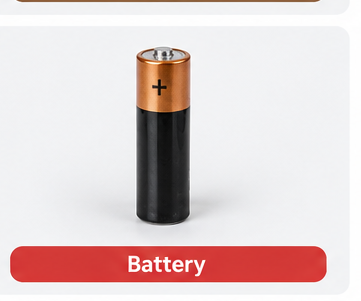


Classes: ['battery', 'biological', 'brown-glass', 'cardboard', 'clothes', 'green-glass', 'metal', 'paper', 'plastic', 'shoes', 'trash', 'white-glass']

Model loaded successfully.
Input shape: [  1 224 224   3]
Output shape: [ 1 12]

========== ECOSORT AI ==========
Mode: SINGLE
Image size: (361, 301)

Predicted category: battery
Model score: 91.23%

Top 3 predictions:
1. battery: 91.23%
2. metal: 5.61%
3. brown-glass: 2.26%

Suggested collection: Special battery collection point
Advice: Keep batteries separate. Never put them in ordinary bins.

IMPORTANT:
- Model scores are not a guarantee of real-world accuracy.
- Check preprocessing and class order against training.
- Bin colours and accepted materials vary by location.


In [341]:

import os
import json
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files
from IPython.display import display

# ==========================================
# 1. SETTINGS
# ==========================================
json_path = "/content/ecosort_final/ecosort_class_names.json"
model_path = "/content/ecosort_final/ecosort_ai_final.tflite"

# Choose "single" or "multiple"
IMAGE_MODE = "single"

# True ONLY if your model was trained with
# MobileNetV2 preprocessing: pixel / 127.5 - 1
USE_MOBILENETV2_PREPROCESSING = False

CONFIDENCE_THRESHOLD = 0.50

# ==========================================
# 2. UPLOAD IMAGE
# ==========================================
print("Upload an image of waste:")
uploaded = files.upload()

if not uploaded:
    raise ValueError("No image was uploaded. Please try again.")

image_path = next(iter(uploaded.keys()))

try:
    image = Image.open(image_path).convert("RGB")
except Exception as e:
    raise ValueError(f"Could not open uploaded image: {e}")

print("\nUploaded image:", image_path)
print("Image dimensions:", image.size)

display(image)

if IMAGE_MODE not in ("single", "multiple"):
    raise ValueError("IMAGE_MODE must be 'single' or 'multiple'.")

# ==========================================
# 3. CHECK FILES
# ==========================================
if not os.path.exists(json_path):
    raise FileNotFoundError(
        f"Class mapping file not found: {json_path}"
    )

if not os.path.exists(model_path):
    raise FileNotFoundError(
        f"TFLite model not found: {model_path}"
    )

# ==========================================
# 4. LOAD CLASS NAMES
# ==========================================
with open(json_path, "r") as f:
    class_mapping = json.load(f)

if isinstance(class_mapping, list):
    class_names = class_mapping
elif isinstance(class_mapping, dict):
    try:
        class_names = [
            class_mapping[str(i)]
            if str(i) in class_mapping
            else class_mapping[i]
            for i in range(len(class_mapping))
        ]
    except (KeyError, TypeError):
        raise ValueError(
            "Unexpected class mapping format. Check the JSON file."
        )
else:
    raise ValueError("Unsupported class mapping format.")

print("\nClasses:", class_names)

# ==========================================
# 5. LOAD TFLITE MODEL
# ==========================================
interpreter = tf.lite.Interpreter(model_path=model_path)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()[0]
output_details = interpreter.get_output_details()[0]

input_index = input_details["index"]
output_index = output_details["index"]
input_dtype = input_details["dtype"]
output_dtype = output_details["dtype"]
input_shape = input_details["shape"]

if len(input_shape) != 4 or list(input_shape[1:]) != [224, 224, 3]:
    raise ValueError(
        f"Expected model input [1, 224, 224, 3], got {input_shape}"
    )

print("\nModel loaded successfully.")
print("Input shape:", input_shape)
print("Output shape:", output_details["shape"])

# ==========================================
# 6. WASTE DISPOSAL GUIDANCE
# ==========================================
bin_guidance = {
    "battery": (
        "Special battery collection point",
        "Keep batteries separate. Never put them in ordinary bins."
    ),
    "biological": (
        "Green bin / organic waste collection",
        "Compost suitable food and garden waste where possible."
    ),
    "brown-glass": (
        "Glass recycling collection",
        "Keep glass separate and follow local recycling rules."
    ),
    "cardboard": (
        "Dry recyclable waste collection",
        "Keep cardboard clean and dry; flatten before recycling."
    ),
    "clothes": (
        "Textile collection point",
        "Donate wearable clothes or use textile collection services."
    ),
    "green-glass": (
        "Glass recycling collection",
        "Keep glass separate and follow local recycling rules."
    ),
    "metal": (
        "Metal recycling collection",
        "Use a local metal recycler or accepted dry-waste service."
    ),
    "paper": (
        "Dry recyclable waste collection",
        "Keep paper clean and dry for recycling."
    ),
    "plastic": (
        "Plastic recycling collection",
        "Check the plastic type and local recycling acceptance."
    ),
    "shoes": (
        "Footwear collection point",
        "Donate usable shoes or find a suitable collection point."
    ),
    "trash": (
        "Residual waste collection",
        "Follow your local rules for non-recyclable waste."
    ),
    "white-glass": (
        "Glass recycling collection",
        "Keep glass separate and follow local recycling rules."
    )
}

# ==========================================
# 7. PREPARE IMAGE
# ==========================================
def create_crops(img, mode):
    if mode == "single":
        return [("Full image", img)]

    w, h = img.size
    crop_w = max(1, int(w * 0.60))
    crop_h = max(1, int(h * 0.60))

    positions = [
        ("Top-left", 0, 0),
        ("Top-right", w - crop_w, 0),
        ("Bottom-left", 0, h - crop_h),
        ("Bottom-right", w - crop_w, h - crop_h)
    ]

    return [
        (name, img.crop((left, top, left + crop_w, top + crop_h)))
        for name, left, top in positions
    ]


def prepare_image(img):
    img = img.convert("RGB").resize((224, 224))

    # The model already contains a Rescaling layer.
    # Pass raw float32 pixels in the 0–255 range.
    arr = np.asarray(img, dtype=np.float32)
    arr = np.expand_dims(arr, axis=0)

    if np.issubdtype(input_dtype, np.integer):
        scale, zero_point = input_details[0]["quantization"]

        if scale <= 0:
            raise ValueError("Invalid input quantization scale.")

        arr = np.round(arr / scale + zero_point)
        limits = np.iinfo(input_dtype)
        arr = np.clip(arr, limits.min, limits.max)

    return arr.astype(input_dtype)


# ==========================================
# 8. PREDICT IMAGE
# ==========================================
def predict_crop(img):
    arr = prepare_image(img)

    interpreter.set_tensor(input_index, arr)
    interpreter.invoke()

    raw_output = interpreter.get_tensor(output_index)[0]

    # Dequantize output if model output is integer-based.
    if np.issubdtype(output_dtype, np.integer):
        scale, zero_point = output_details["quantization"]

        if scale <= 0:
            raise ValueError(
                "Invalid output quantization scale."
            )

        scores = (
            raw_output.astype(np.float32) - zero_point
        ) * scale
    else:
        scores = raw_output.astype(np.float32)

    if len(scores) != len(class_names):
        raise ValueError(
            f"Model returned {len(scores)} scores, "
            f"but JSON contains {len(class_names)} classes."
        )

    if not np.all(np.isfinite(scores)):
        raise ValueError("Model returned invalid prediction values.")

    # Use probabilities directly when they look like probabilities;
    # otherwise apply softmax, suitable for logits.
    # Confirm the model's final activation for definitive interpretation.
    is_probability_output = (
        np.all(scores >= 0)
        and np.all(scores <= 1)
        and np.isclose(np.sum(scores), 1.0, atol=0.02)
    )

    if is_probability_output:
        probabilities = scores
    else:
        shifted = scores - np.max(scores)
        exp_scores = np.exp(shifted)
        probabilities = exp_scores / np.sum(exp_scores)

    return probabilities

# ==========================================
# 9. RUN PREDICTION
# ==========================================
crops = create_crops(image, IMAGE_MODE)
results = []

for region_name, crop_image in crops:
    probabilities = predict_crop(crop_image)
    best_index = int(np.argmax(probabilities))

    results.append({
        "region": region_name,
        "waste": class_names[best_index],
        "confidence": float(probabilities[best_index]),
        "probabilities": probabilities
    })

# ==========================================
# 10. DISPLAY RESULTS
# ==========================================
print("\n========== ECOSORT AI ==========")
print("Mode:", IMAGE_MODE.upper())
print("Image size:", image.size)

if IMAGE_MODE == "single":
    result = results[0]
    predicted_waste = result["waste"]
    confidence = result["confidence"]

    print("\nPredicted category:", predicted_waste)
    print(f"Model score: {confidence * 100:.2f}%")

    print("\nTop 3 predictions:")
    probabilities = result["probabilities"]
    top_indices = np.argsort(probabilities)[::-1][:3]

    for rank, idx in enumerate(top_indices, start=1):
        print(
            f"{rank}. {class_names[idx]}: "
            f"{probabilities[idx] * 100:.2f}%"
        )

    if confidence < CONFIDENCE_THRESHOLD:
        print(
            "\nLOW CONFIDENCE: Please verify the category "
            "or upload a clearer image."
        )

    bin_name, advice = bin_guidance.get(
        predicted_waste,
        ("Check local guidance", "Confirm with your local authority.")
    )

    print("\nSuggested collection:", bin_name)
    print("Advice:", advice)

else:
    print("\n========== REGION PREDICTIONS ==========")

    for result in results:
        print(
            f"\n{result['region']}: {result['waste']} "
            f"({result['confidence'] * 100:.2f}%)"
        )

        if result["confidence"] < CONFIDENCE_THRESHOLD:
            print("Low confidence: manually verify this region.")

        bin_name, advice = bin_guidance.get(
            result["waste"],
            ("Check local guidance", "Confirm with your local authority.")
        )

        print("Suggested collection:", bin_name)
        print("Advice:", advice)

    print(
        "\nNote: overlapping crops can classify the same item more "
        "than once or miss items. This is not object detection."
    )

print("\nIMPORTANT:")
print("- Model scores are not a guarantee of real-world accuracy.")
print("- Check preprocessing and class order against training.")
print("- Bin colours and accepted materials vary by location.")
